# trackver — ECMWF ensemble tropical cyclone forecast against IBTrACS observations

This notebook does what the `./trackver` command does, step by step, and shows the plots here
instead of saving them:

1. downloads the latest IBTrACS *last3years* best-track file and finds the storm,
2. downloads the chosen run's BUFR track file from the `ecmwf-static-datasets` S3 bucket,
3. plots the wind and pressure meteogram and the track plume map, with the observations on top.

The code lives in the `trackver` program next to this notebook; the notebook loads it as a module.

In [1]:
#Uncomment and run pip install if you haven't installed the requirements yet.

#pip install -r requirements.txt

## Settings

* `STORM` — storm name, any case, or IBTrACS storm id (SID). If the name was reused, the storm observed at `RUN` is used.
* `RUN` — base time of the forecast run, `YYYYMMDDHH`: 00, 06, 12 or 18 UTC, while the storm was observed.
  The 00 and 12 UTC runs go up to 360 h ahead; the 06 and 18 UTC runs go up to 144 h.

In [1]:
STORM = "GARANCE"
RUN = "2025022512"      # YYYYMMDDHH
MAX_HOURS = 240         # last forecast step plotted

In [2]:
from datetime import datetime
from importlib.machinery import SourceFileLoader
from importlib.util import module_from_spec, spec_from_loader

# load the trackver program (a script without the .py ending) as a module
loader = SourceFileLoader("trackver", "trackver")
tv = module_from_spec(spec_from_loader("trackver", loader))
loader.exec_module(tv)

## 1. Observations

The IBTrACS file is downloaded into `obs/`.

In [3]:
base = datetime.strptime(str(RUN), "%Y%m%d%H")

ibtracs = tv.read_ibtracs(tv.download_ibtracs())
track = tv.choose_storm(ibtracs, STORM, at=base)    # the storm observed at the run's base time
obs, obs_label = tv.observed_intensity(track)

name, sid = track.NAME.iloc[0], "+".join(track.SID.unique())
print(f"{name} ({sid}), {len(track)} positions, intensity from {obs_label}")
obs.head()

IBTrACS: https://www.ncei.noaa.gov/data/international-best-track-archive-for-climate-stewardship-ibtracs/v04r01/access/csv/ibtracs.last3years.list.v04r01.csv
GARANCE (2025054S17051), 79 positions, intensity from IBTrACS: reunion 10-min


,wind,mslp,LAT,LON
time,,,,
2025-02-23 06:00:00,20.0,1010.0,-17.2,50.7
2025-02-23 12:00:00,20.0,1009.0,-17.4,51.3
2025-02-23 18:00:00,25.0,1008.0,-17.9,51.1
2025-02-24 00:00:00,25.0,1007.0,-17.9,50.4
2025-02-24 06:00:00,25.0,1006.0,-17.9,51.1


## 2. Download the forecast

The storm is found by name when the analysed centre is close to the observed one, otherwise as the
analysed storm nearest the observed position (e.g. before it was named).

In [4]:
bases = tv.candidate_runs(track, obs)      # runs during the storm that are on S3
if base not in bases:
    raise tv.TrackverError(f"no run at {base:%Y-%m-%d %H} UTC for {name}; runs are available "
                           f"from {bases[0]:%Y%m%d%H} to {bases[-1]:%Y%m%d%H}, every 6 hours")

storm = tv.forecast_storm(base, track)
meteogram, plumes = tv.make_plots(storm, track, base, obs, obs_label, MAX_HOURS)
tv.plt.close("all")     # shown one by one below

ecm_wf_20250225T120000Z_20250312T120000Z_ifs-ens_od_enfo_tf_360h.bufr:   0%|          | 0.00/1.32M [00:00<?, ?…

Found GARANCE in the forecast by name.


## 3. Meteogram

The boxes span the 51-member ensemble (50 perturbed members plus the low-resolution control): whiskers
from the minimum to the maximum, the box over the interquartile range, the median inside. The black lines
are the high-resolution forecast and the control, the dashed line the ensemble mean, and the red stars
the observations at the forecast steps.

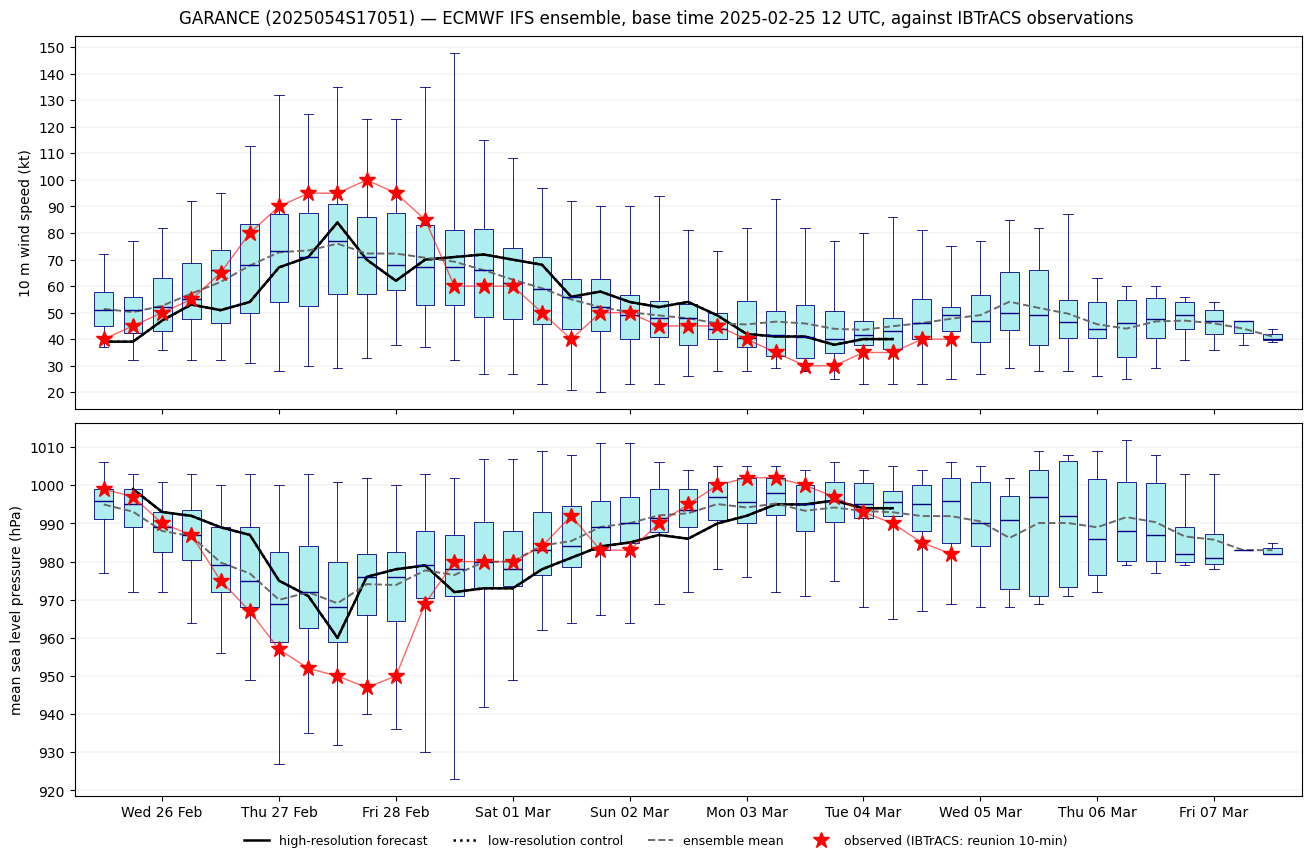

In [5]:
meteogram

## 4. Plume map

Every member's track, coloured by lead time in 24-hour bands, with the high-resolution forecast and the
control in black. The red dots are the observed positions at the forecast steps, every 6 hours.

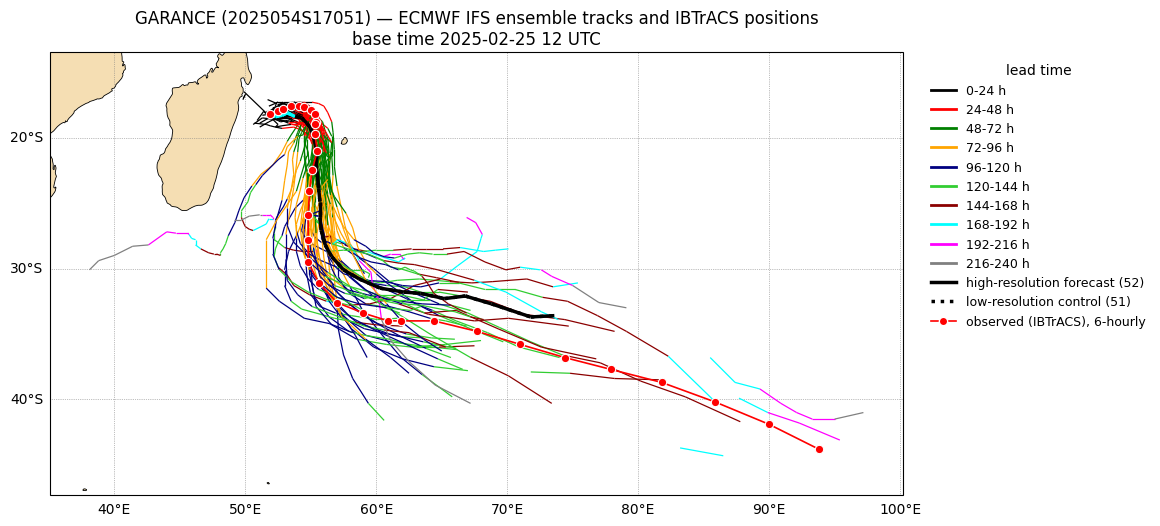

In [6]:
plumes